# CIFAR100 simplex scale sweep summary

This notebook loads `cifar100_simplex_scale_sweep.json` and plots final test
accuracy vs. simplex scale `s` (the pairwise distance between class means) for
Simplex LDA only. Latent dimension and covariance are held fixed by the sweep.
Mean markers, solid connecting lines, and a colored ±2 population standard
deviation band are computed across the runs stored in the file. The background
is transparent with a faint grid. The plot is saved at **600 dpi**.


In [1]:
from pathlib import Path
import json
import statistics as stats
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.style.use("ggplot")


In [2]:
# Locate the results from the plots folder, simplex-lda folder, or workspace root.
candidates = [
    Path("cifar100_simplex_scale_sweep.json"),
    Path("plots/cifar100_simplex_scale_sweep.json"),
    Path("simplex-lda/plots/cifar100_simplex_scale_sweep.json"),
]
sweep_file = next((p for p in candidates if p.is_file()), None)
if sweep_file is None:
    raise FileNotFoundError("Cannot find cifar100_simplex_scale_sweep.json")

with sweep_file.open() as f:
    data = json.load(f)

# Recompute statistics from individual runs rather than the cached summaries.
runs_by_scale = {
    float(scale): [run["final_test"] for run in metrics["runs"]]
    for scale, metrics in data["DeepLDA"].items()
}
scales = sorted(runs_by_scale)
mean_acc = [stats.mean(runs_by_scale[s]) for s in scales]
std_acc = [stats.pstdev(runs_by_scale[s]) for s in scales]
summary_rows = [
    {"scale": s, "mean_test_acc": mean, "std": std, "runs": runs_by_scale[s]}
    for s, mean, std in zip(scales, mean_acc, std_acc)
]

print(f"Fixed D={data['latent_dim']}, covariance={data['covariance_type']}, "
      f"epochs={data['epochs']}")
summary_rows


Fixed D=99, covariance=identity, epochs=100


[{'scale': 1.0,
  'mean_test_acc': 0.6422333333333333,
  'std': 0.0035518383346593006,
  'runs': [0.6379, 0.6422, 0.6466]},
 {'scale': 2.0,
  'mean_test_acc': 0.6413666666666666,
  'std': 0.008997160045752729,
  'runs': [0.637, 0.6332, 0.6539]},
 {'scale': 4.0,
  'mean_test_acc': 0.642,
  'std': 0.003265986323710907,
  'runs': [0.638, 0.642, 0.646]},
 {'scale': 6.0,
  'mean_test_acc': 0.6464,
  'std': 0.005957068630347212,
  'runs': [0.6381, 0.6518, 0.6493]},
 {'scale': 8.0,
  'mean_test_acc': 0.6474666666666666,
  'std': 0.0011556623882239862,
  'runs': [0.6466, 0.6467, 0.6491]},
 {'scale': 10.0,
  'mean_test_acc': 0.6467666666666666,
  'std': 0.0017913371790059117,
  'runs': [0.6475, 0.6443, 0.6485]},
 {'scale': 12.0,
  'mean_test_acc': 0.6453,
  'std': 0.0035898003658513572,
  'runs': [0.6417, 0.644, 0.6502]}]

Saved plot to cifar100_simplex_scale_summary.png (600 dpi)


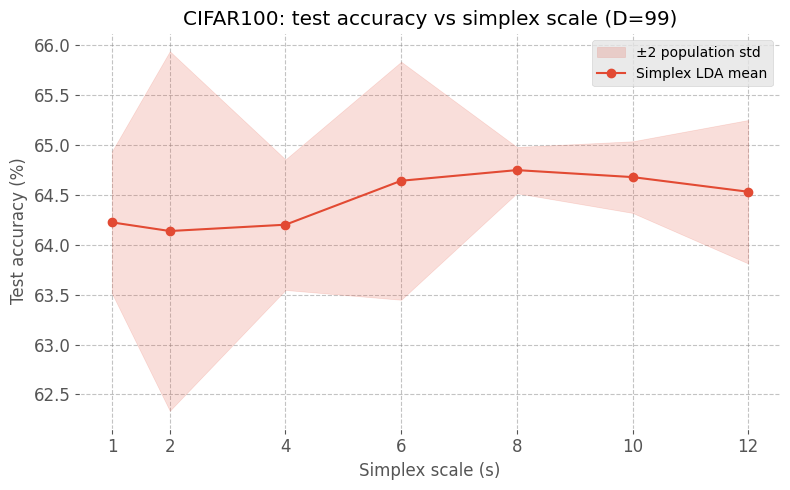

In [3]:
# Plot the mean and ±2 population std band, matching the latent-dimension summary.
fig, ax = plt.subplots(figsize=(8, 5))
color = "C0"
std_2 = [2 * s for s in std_acc]
lower = [m - s for m, s in zip(mean_acc, std_2)]
upper = [m + s for m, s in zip(mean_acc, std_2)]
ax.fill_between(scales, lower, upper, color=color, alpha=0.18,
                label="±2 population std")
ax.plot(scales, mean_acc, marker="o", color=color, linewidth=1.5,
        label="Simplex LDA mean")

ax.set_facecolor("none")
fig.patch.set_alpha(0)
ax.grid(True, color="#888888", alpha=0.5, linestyle="--", linewidth=0.8)
ax.set_xlabel("Simplex scale (s)")
ax.set_ylabel("Test accuracy (%)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{100 * value:.1f}"))
ax.set_title(f"CIFAR100: test accuracy vs simplex scale (D={data['latent_dim']})")
ax.set_xticks(scales)
ax.legend()
ax.tick_params(labelsize=12)
fig.tight_layout()

plot_file = sweep_file.with_name("cifar100_simplex_scale_summary.png")
fig.savefig(plot_file, dpi=600, bbox_inches="tight", transparent=True)
print(f"Saved plot to {plot_file} (600 dpi)")
plt.show()
